In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("First review:", X_train[0][:20])
print("Sentiment:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Sentiment: 1


In [ ]:
print("0 = Negative Review")
print("1 = Positive Review")

print("First 10 labels:", y_train[:10])

0 = Negative Review
1 = Positive Review
First 10 labels: [1 0 0 1 0 0 1 0 1 0]


In [ ]:
max_length = 200

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [ ]:
lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        input_length=max_length
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 63s 382ms/step - accuracy: 0.5147 - loss: 0.6916 - val_accuracy: 0.5436 - val_loss: 0.6837
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 94s 458ms/step - accuracy: 0.5861 - loss: 0.6600 - val_accuracy: 0.5886 - val_loss: 0.6407
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 68s 370ms/step - accuracy: 0.6859 - loss: 0.5640 - val_accuracy: 0.7524 - val_loss: 0.5495
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 367ms/step - accuracy: 0.6514 - loss: 0.5982 - val_accuracy: 0.5418 - val_loss: 0.6809
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 60s 385ms/step - accuracy: 0.6435 - loss: 0.5801 - val_accuracy: 0.6486 - val_loss: 0.6302


In [ ]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test, y_test
)

print("LSTM Test Loss:", lstm_loss)
print("LSTM Test Accuracy:", lstm_accuracy * 100, "%")

226/782 ━━━━━━━━━━━━━━━━━━━━ 39s 72ms/step - accuracy: 0.7455 - loss: 0.5629

In [ ]:
gru_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        input_length=max_length
    ),

    GRU(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 69s 417ms/step - accuracy: 0.5075 - loss: 0.6928 - val_accuracy: 0.5220 - val_loss: 0.6907
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 69s 439ms/step - accuracy: 0.5725 - loss: 0.6630 - val_accuracy: 0.5380 - val_loss: 0.6833


In [ ]:
gru_loss, gru_accuracy = gru_model.evaluate(
    X_test, y_test
)

print("GRU Test Loss:", gru_loss)
print("GRU Test Accuracy:", gru_accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.5261 - loss: 0.6907
GRU Test Loss: 0.6907266974449158
GRU Test Accuracy: 52.60800123214722 %


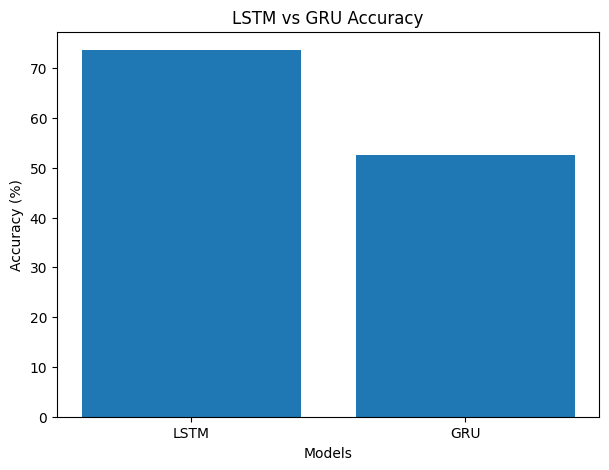

LSTM Accuracy: 73.64 %
GRU Accuracy: 52.61 %


In [ ]:
models = ['LSTM', 'GRU']

accuracies = [
    lstm_accuracy * 100,
    gru_accuracy * 100
]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.title("LSTM vs GRU Accuracy")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")

plt.show()

for model, accuracy in zip(models, accuracies):
    print(model, "Accuracy:", round(accuracy, 2), "%")

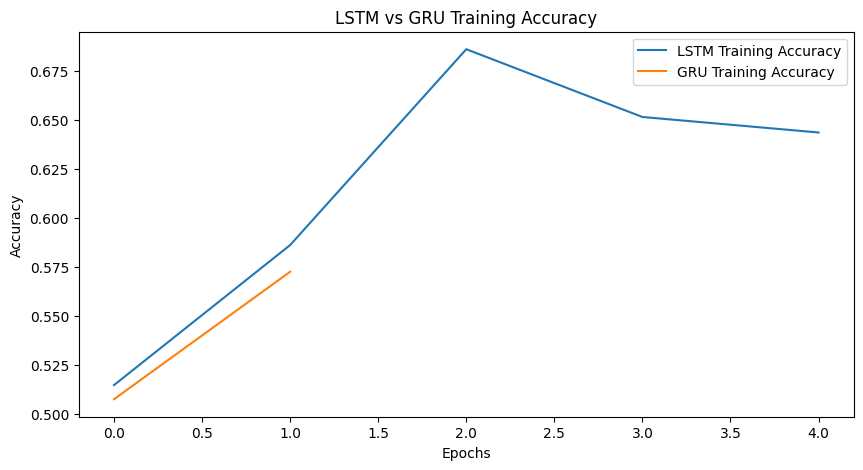

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history['accuracy'],
    label='LSTM Training Accuracy'
)

plt.plot(
    gru_history.history['accuracy'],
    label='GRU Training Accuracy'
)

plt.title("LSTM vs GRU Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

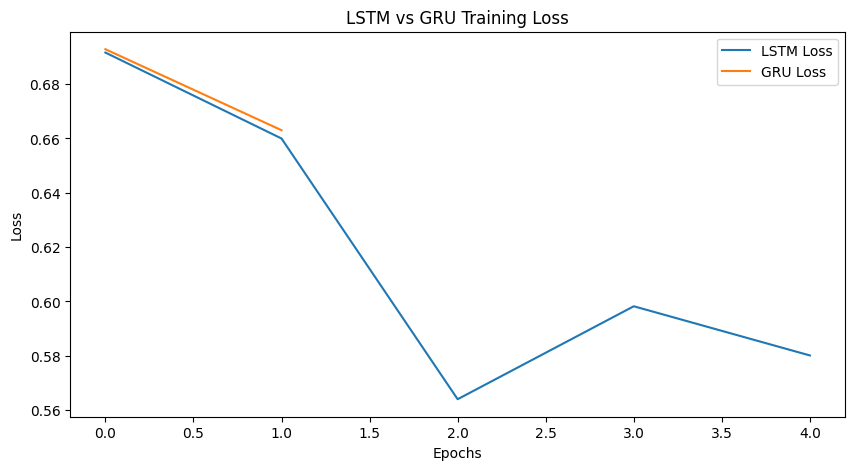

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history['loss'],
    label='LSTM Loss'
)

plt.plot(
    gru_history.history['loss'],
    label='GRU Loss'
)

plt.title("LSTM vs GRU Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [ ]:
y_pred = (gru_model.predict(X_test) > 0.5).astype("int32")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.19      0.29     12500
           1       0.52      0.86      0.64     12500

    accuracy                           0.53     25000
   macro avg       0.55      0.53      0.47     25000
weighted avg       0.55      0.53      0.47     25000

Confusion Matrix:
[[ 2423 10077]
 [ 1771 10729]]


In [ ]:
word_index = imdb.get_word_index()

def predict_sentiment(review):

    words = review.lower().split()

    sequence = [1]

    for word in words:
        index = word_index.get(word, 2) + 3

        if index >= vocab_size:
            index = 2

        sequence.append(index)

    padded = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    prediction = gru_model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Positive Review")
    else:
        print("Negative Review")

    print("Sentiment Score:", round(float(prediction), 4))


predict_sentiment(
    "This movie is excellent and wonderful. I really enjoyed it"
)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive Review
Sentiment Score: 0.5104
